# Radar vs. Drone Ground Truth Analysis

## Project Overview

This project evaluates highway traffic radar measurements against drone ground truth using Python.

Analysis includes matching radar detection to ground truth, measuring position/speed difference, evaluating performance, and visualizing measurement and errors.

**Dataset:** DRaT (Drone and Radar Trajoectories).

**Tools:** Python, pands, NumPy, SciPy, Matplotlib.

Methodolgy used Hungarian assignment witha 40-foot acceptable threshold.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
radar = pd.read_csv("../data/radar.csv")
truth = pd.read_csv("../data/drone_GT.csv")


In [3]:
print("Radar shape:", radar.shape)
print("Truth shape:", truth.shape)


Radar shape: (282712, 14)
Truth shape: (392707, 13)


In [4]:
radar.head()

,track_id,timestamp,lat,lon,utm_x,utm_y,local_x_ft,local_y_ft,speed_mps,length_m,width_m,object_type,track_quality,lane_id
0,10241,1.759512e+09,32.661346,-97.275286,661738.580308,3.615059e+06,35.134781,421.383392,25.568294,7.503164,2.5,60,68.590347,2
1,10241,1.759512e+09,32.661347,-97.275259,661741.056621,3.615059e+06,35.252827,413.239716,25.506933,7.597441,2.5,60,68.547340,2
2,10241,1.759512e+09,32.661347,-97.275219,661744.853863,3.615059e+06,34.722317,400.791779,25.481860,7.697407,2.5,60,72.106964,2
3,10241,1.759512e+09,32.661347,-97.275195,661747.120228,3.615059e+06,34.145607,393.376831,25.264557,8.182469,2.5,60,69.651100,2
4,10241,1.759512e+09,32.661346,-97.275165,661749.887396,3.615059e+06,33.700581,384.308899,25.447863,8.188196,2.5,60,72.427681,2


In [5]:
truth.head()


,track_id,timestamp,lat,lon,utm_x,utm_y,local_x_ft,local_y_ft,speed_mps,accel_mps2,length_m,width_m,vehicle_class
0,1,1.759512e+09,32.661390,-97.274355,661825.840,3615065.070,39.832362,134.388594,34.430768,0.392,4.75,2.11,0
1,2,1.759512e+09,32.661345,-97.274558,661806.854,3615059.740,25.849874,197.557639,30.838051,0.110,4.86,2.11,0
2,3,1.759512e+09,32.661379,-97.274935,661771.424,3615062.920,42.755378,313.034161,30.483443,-0.110,22.78,3.52,2
3,4,1.759512e+09,32.661414,-97.275048,661760.806,3615066.666,56.970837,347.129754,33.417901,-0.252,5.05,2.15,0
4,5,1.759512e+09,32.661346,-97.275105,661755.524,3615059.036,32.944414,365.829499,29.346869,-0.720,4.81,2.15,0


In [6]:
radar.info()

<class 'pandas.DataFrame'>
RangeIndex: 282712 entries, 0 to 282711
Data columns (total 14 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   track_id       282712 non-null  int64  
 1   timestamp      282712 non-null  float64
 2   lat            282712 non-null  float64
 3   lon            282712 non-null  float64
 4   utm_x          282712 non-null  float64
 5   utm_y          282712 non-null  float64
 6   local_x_ft     282712 non-null  float64
 7   local_y_ft     282712 non-null  float64
 8   speed_mps      282712 non-null  float64
 9   length_m       282712 non-null  float64
 10  width_m        282712 non-null  float64
 11  object_type    282712 non-null  int64  
 12  track_quality  282712 non-null  float64
 13  lane_id        282712 non-null  int64  
dtypes: float64(11), int64(3)
memory usage: 30.2 MB


In [7]:
truth.info()

<class 'pandas.DataFrame'>
RangeIndex: 392707 entries, 0 to 392706
Data columns (total 13 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   track_id       392707 non-null  int64  
 1   timestamp      392707 non-null  float64
 2   lat            392707 non-null  float64
 3   lon            392707 non-null  float64
 4   utm_x          392707 non-null  float64
 5   utm_y          392707 non-null  float64
 6   local_x_ft     392707 non-null  float64
 7   local_y_ft     392707 non-null  float64
 8   speed_mps      392409 non-null  float64
 9   accel_mps2     392324 non-null  float64
 10  length_m       389521 non-null  float64
 11  width_m        389521 non-null  float64
 12  vehicle_class  392707 non-null  int64  
dtypes: float64(11), int64(2)
memory usage: 38.9 MB


In [8]:
print("Radar start:", radar["timestamp"].min())
print("Radar end:  ", radar["timestamp"].max())
#do the timestamps begin and end at the same time?
print("Truth start:", truth["timestamp"].min())
print("Truth end:  ", truth["timestamp"].max())
#do the timestamps begin and end at the same time?


Radar start: 1759512449.11
Radar end:   1759520575.93
Truth start: 1759512449.11
Truth end:   1759520575.93


In [9]:
radar_times = set(radar["timestamp"])
truth_times = set(truth["timestamp"])
#unique radar timestamps, unique truth timestamps, and shared timestamps

print("Unique radar timestamps:", len(radar_times))
print("Unique truth timestamps:", len(truth_times))
print("Shared timestamps:", len(radar_times & truth_times))


Unique radar timestamps: 38537
Unique truth timestamps: 38503
Shared timestamps: 38503


In [10]:
first_time = min(radar_times & truth_times)
#first shared data timestamp

radar_frame = radar[radar["timestamp"] == first_time]
truth_frame = truth[truth["timestamp"] == first_time]
#how many radar detections and truth vehicles are present at the first shared timestamp

print("Timestamp:", first_time)
print("Radar detections:", len(radar_frame))
print("Truth vehicles:", len(truth_frame))


Timestamp: 1759512449.11
Radar detections: 4
Truth vehicles: 5


In [11]:
print("RADAR")
print(radar_frame[["track_id", "local_x_ft", "local_y_ft", "speed_mps"]])
#our 4 radar detections

print("\nTRUTH")
print(truth_frame[["track_id", "local_x_ft", "local_y_ft", "speed_mps"]])
#our 5 truth detections/vehicles


RADAR
    track_id  local_x_ft  local_y_ft  speed_mps
38     10258   42.113449  284.974487  28.815837
60     10261   27.790186  194.404053  30.437614
73     10262   41.503681  133.218750  33.751753
79     10271   31.796240  358.381409  29.503258

TRUTH
   track_id  local_x_ft  local_y_ft  speed_mps
0         1   39.832362  134.388594  34.430768
1         2   25.849874  197.557639  30.838051
2         3   42.755378  313.034161  30.483443
3         4   56.970837  347.129754  33.417901
4         5   32.944414  365.829499  29.346869


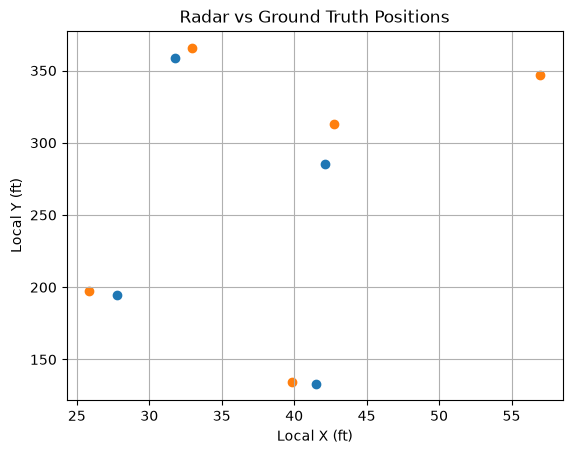

In [12]:
plt.scatter(
    radar_frame["local_x_ft"],
    radar_frame["local_y_ft"],
    label="Radar"
)

plt.scatter(
    truth_frame["local_x_ft"],
    truth_frame["local_y_ft"],
    label="Ground Truth"
)

plt.xlabel("Local X (ft)")
plt.ylabel("Local Y (ft)")
plt.title("Radar vs Ground Truth Positions")
#plt.legend()
plt.grid()

plt.show()
#scatter plot of our x,y coordinates for each data set

In [13]:
from scipy.spatial.distance import cdist

radar_positions = radar_frame[["local_x_ft", "local_y_ft"]]
truth_positions = truth_frame[["local_x_ft", "local_y_ft"]]

distances = cdist(radar_positions, truth_positions)
#calculate the pairwise distances between radar and truth positions
distances

array([[150.60316905,  88.91686671,  28.06701583,  63.90633141,
         81.37323988],
       [ 61.21167635,   3.70269028, 119.57031193, 155.48842445,
        171.50291427],
       [  2.04005936,  66.21581617, 179.81976749, 214.46946297,
        232.76817137],
       [224.13692339, 160.93366418,  46.65271275,  27.57462737,
          7.53606981]])

In [14]:
distance_df = pd.DataFrame(
    distances,
    index=radar_frame["track_id"],
    columns=truth_frame["track_id"]
)

distance_df.index.name = "radar_track_id"
distance_df.columns.name = "truth_track_id"

#create a DataFrame to store the pairwise distances between radar and truth positions
distance_df

truth_track_id,1,2,3,4,5
radar_track_id,,,,,
10258,150.603169,88.916867,28.067016,63.906331,81.373240
10261,61.211676,3.702690,119.570312,155.488424,171.502914
10262,2.040059,66.215816,179.819767,214.469463,232.768171
10271,224.136923,160.933664,46.652713,27.574627,7.536070


In [15]:
from scipy.optimize import linear_sum_assignment

radar_indices, truth_indices = linear_sum_assignment(distances)

print("Radar indices:", radar_indices)
print("Truth indices:", truth_indices)

#display the matched pairs

Radar indices: [0 1 2 3]
Truth indices: [2 1 0 4]


In [16]:
for radar_idx, truth_idx in zip(radar_indices, truth_indices):
    radar_id = radar_frame.iloc[radar_idx]["track_id"]
    truth_id = truth_frame.iloc[truth_idx]["track_id"]
    distance = distances[radar_idx, truth_idx]

    print(
        f"Radar {int(radar_id)} -> "
        f"Truth {int(truth_id)} -> "
        f"{distance:.2f} ft"
    )
#print the matched radar and truth track IDs along with their distances

Radar 10258 -> Truth 3 -> 28.07 ft
Radar 10261 -> Truth 2 -> 3.70 ft
Radar 10262 -> Truth 1 -> 2.04 ft
Radar 10271 -> Truth 5 -> 7.54 ft


In [17]:
matches = []

for radar_idx, truth_idx in zip(radar_indices, truth_indices):
    radar_id = radar_frame.iloc[radar_idx]["track_id"]
    truth_id = truth_frame.iloc[truth_idx]["track_id"]
    distance = distances[radar_idx, truth_idx]

    matches.append({
        "radar_track_id": int(radar_id),
        "truth_track_id": int(truth_id),
        "distance_ft": distance
    })

#create a DataFrame to store the matched radar and truth track IDs along with their distances
matches_df = pd.DataFrame(matches)

matches_df

,radar_track_id,truth_track_id,distance_ft
0,10258,3,28.067016
1,10261,2,3.702690
2,10262,1,2.040059
3,10271,5,7.536070


In [18]:
for radar_idx, truth_idx in zip(radar_indices, truth_indices):
    radar_speed = radar_frame.iloc[radar_idx]["speed_mps"]
    truth_speed = truth_frame.iloc[truth_idx]["speed_mps"]

    speed_difference = abs(radar_speed - truth_speed)

    print(
        f"Radar {int(radar_frame.iloc[radar_idx]['track_id'])} -> "
        f"Truth {int(truth_frame.iloc[truth_idx]['track_id'])}: "
        f"Radar speed = {radar_speed:.2f} m/s, "
        f"Truth speed = {truth_speed:.2f} m/s, "
        f"Difference = {speed_difference:.2f} m/s"
    )
#print the matched radar and truth track IDs along with their speed differences


Radar 10258 -> Truth 3: Radar speed = 28.82 m/s, Truth speed = 30.48 m/s, Difference = 1.67 m/s
Radar 10261 -> Truth 2: Radar speed = 30.44 m/s, Truth speed = 30.84 m/s, Difference = 0.40 m/s
Radar 10262 -> Truth 1: Radar speed = 33.75 m/s, Truth speed = 34.43 m/s, Difference = 0.68 m/s
Radar 10271 -> Truth 5: Radar speed = 29.50 m/s, Truth speed = 29.35 m/s, Difference = 0.16 m/s


In [19]:
radar_track = radar[radar["track_id"] == 10258]
truth_track = truth[truth["track_id"] == 3]

print("Radar observations:", len(radar_track))
print("Truth observations:", len(truth_track))

print("Radar time range:")
print(radar_track["timestamp"].min(), radar_track["timestamp"].max())

print("Truth time range:")
print(truth_track["timestamp"].min(), truth_track["timestamp"].max())
#print the time ranges of the radar and truth tracks

Radar observations: 22
Truth observations: 26
Radar time range:
1759512449.11 1759512451.739
Truth time range:
1759512449.11 1759512452.242


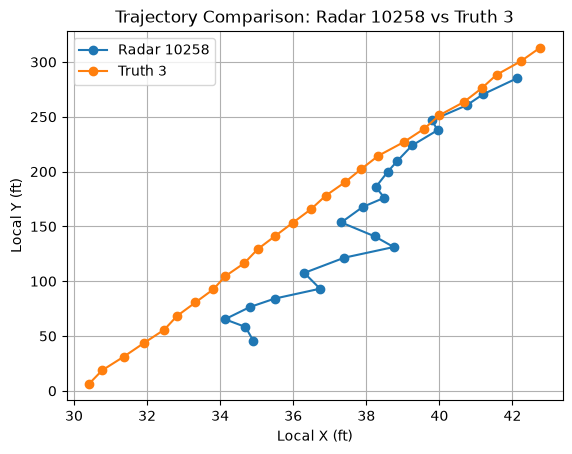

In [20]:
plt.plot(
    radar_track["local_x_ft"],
    radar_track["local_y_ft"],
    marker="o",
    label="Radar 10258"
)

plt.plot(
    truth_track["local_x_ft"],
    truth_track["local_y_ft"],
    marker="o",
    label="Truth 3"
)

plt.xlabel("Local X (ft)")
plt.ylabel("Local Y (ft)")
plt.title("Trajectory Comparison: Radar 10258 vs Truth 3")
plt.legend()
plt.grid()

plt.show()
#plot the trajectories of the radar and truth tracks for visual comparison

In [21]:
track_comparison = pd.merge(
    radar_track,
    truth_track,
    on="timestamp",
    suffixes=("_radar", "_truth")
)

print("Shared observations:", len(track_comparison))

track_comparison[[
    "timestamp",
    "local_x_ft_radar",
    "local_y_ft_radar",
    "local_x_ft_truth",
    "local_y_ft_truth"
]].head()
#print the first few rows of the merged track comparison to verify the alignment of radar and truth observations

Shared observations: 22


,timestamp,local_x_ft_radar,local_y_ft_radar,local_x_ft_truth,local_y_ft_truth
0,1.759512e+09,42.113449,284.974487,42.755378,313.034161
1,1.759512e+09,41.194061,270.516541,42.226688,300.639165
2,1.759512e+09,40.748642,260.540314,41.565729,288.346843
3,1.759512e+09,39.792488,246.764206,41.153771,275.912132
4,1.759512e+09,39.952541,237.820801,40.662848,263.322789


In [22]:
track_comparison["position_error_ft"] = np.sqrt(
    (track_comparison["local_x_ft_radar"] - track_comparison["local_x_ft_truth"])**2
    +
    (track_comparison["local_y_ft_radar"] - track_comparison["local_y_ft_truth"])**2
)

track_comparison[[
    "timestamp",
    "position_error_ft"
]]
#print the position errors for each shared observation

,timestamp,position_error_ft
0,1.759512e+09,28.067016
1,1.759512e+09,30.140318
2,1.759512e+09,27.818531
3,1.759512e+09,29.179696
4,1.759512e+09,25.511878
5,1.759512e+09,27.489982
6,1.759512e+09,29.282008
7,1.759512e+09,27.292729
8,1.759512e+09,28.679038
9,1.759512e+09,26.257539


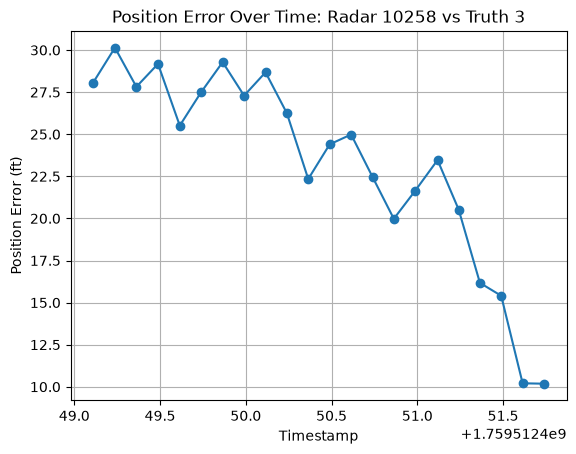

In [23]:
plt.plot(
    track_comparison["timestamp"],
    track_comparison["position_error_ft"],
    marker="o"
)

plt.xlabel("Timestamp")
plt.ylabel("Position Error (ft)")
plt.title("Position Error Over Time: Radar 10258 vs Truth 3")
plt.grid()

plt.show()
#plot position error over time for visual comparison

In [24]:
def match_frame(radar_frame, truth_frame):
    radar_positions = radar_frame[["local_x_ft", "local_y_ft"]]
    truth_positions = truth_frame[["local_x_ft", "local_y_ft"]]

    distances = cdist(radar_positions, truth_positions)

    radar_indices, truth_indices = linear_sum_assignment(distances)

    matches = []

    for radar_idx, truth_idx in zip(radar_indices, truth_indices):
        matches.append({
            "timestamp": radar_frame.iloc[radar_idx]["timestamp"],
            "radar_track_id": int(radar_frame.iloc[radar_idx]["track_id"]),
            "truth_track_id": int(truth_frame.iloc[truth_idx]["track_id"]),
            "distance_ft": distances[radar_idx, truth_idx]
        })

    return pd.DataFrame(matches)
#function to match radar and truth frames based on position using the Hungarian algorithm

In [25]:
test_matches = match_frame(radar_frame, truth_frame)

test_matches
#display the matched radar and truth tracks for the test frame

,timestamp,radar_track_id,truth_track_id,distance_ft
0,1.759512e+09,10258,3,28.067016
1,1.759512e+09,10261,2,3.702690
2,1.759512e+09,10262,1,2.040059
3,1.759512e+09,10271,5,7.536070


In [26]:
#testing on another frame
test_time = sorted(radar_times & truth_times)[1000]

radar_test_frame = radar[radar["timestamp"] == test_time]
truth_test_frame = truth[truth["timestamp"] == test_time]

print("Timestamp:", test_time)
print("Radar detections:", len(radar_test_frame))
print("Truth vehicles:", len(truth_test_frame))

Timestamp: 1759512574.846
Radar detections: 3
Truth vehicles: 5


In [27]:
#testing function on another frame
test_matches_2 = match_frame(radar_test_frame, truth_test_frame)

test_matches_2
#looks good

,timestamp,radar_track_id,truth_track_id,distance_ft
0,1.759513e+09,10756,152,7.866123
1,1.759513e+09,10804,154,1.139459
2,1.759513e+09,10811,153,2.878772


In [28]:
sample_times = sorted(radar_times & truth_times)[:100]

sample_matches = []

for timestamp in sample_times:
    radar_sample = radar[radar["timestamp"] == timestamp]
    truth_sample = truth[truth["timestamp"] == timestamp]

    frame_matches = match_frame(radar_sample, truth_sample)

    frame_matches["timestamp"] = timestamp

    sample_matches.append(frame_matches)

sample_matches_df = pd.concat(sample_matches, ignore_index=True)

sample_matches_df
#display the matched radar and truth tracks for the first 100 sample frames to determine a cutoff

,timestamp,radar_track_id,truth_track_id,distance_ft
0,1.759512e+09,10258,3,28.067016
1,1.759512e+09,10261,2,3.702690
2,1.759512e+09,10262,1,2.040059
3,1.759512e+09,10271,5,7.536070
4,1.759512e+09,10258,3,30.140318
...,...,...,...,...
455,1.759512e+09,10335,19,1.840121
456,1.759512e+09,10336,20,4.750674
457,1.759512e+09,10295,21,5.930434
458,1.759512e+09,10335,19,1.918991


In [29]:
sample_matches_df["distance_ft"].describe()
#display the summary statistics for the distances between matched radar and truth tracks

count    460.000000
mean      18.442928
std       26.768366
min        0.280873
25%        3.626585
50%        6.622601
75%       24.235306
max      172.239185
Name: distance_ft, dtype: float64

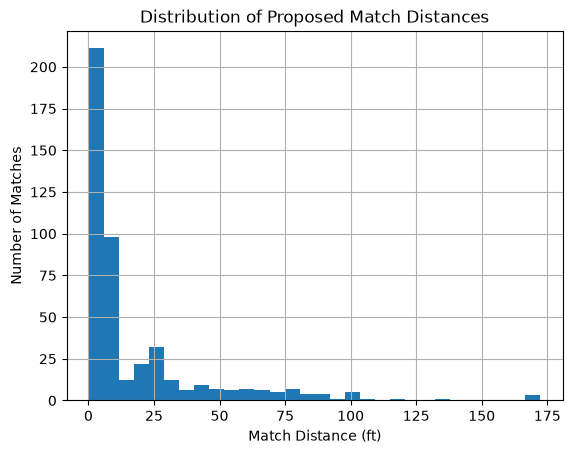

In [30]:
plt.hist(sample_matches_df["distance_ft"], bins=30)

plt.xlabel("Match Distance (ft)")
plt.ylabel("Number of Matches")
plt.title("Distribution of Proposed Match Distances")
plt.grid()
plt.show()
#display the histogram of proposed match distances between radar and truth tracks

In [31]:
thresholds = [5, 10, 15, 20, 25, 30, 50]

for threshold in thresholds:
    count = (sample_matches_df["distance_ft"] <= threshold).sum()
    percent = count / len(sample_matches_df) * 100

    print(
        f"Within {threshold:2} ft: "
        f"{count:3} matches ({percent:.1f}%)"
    )

Within  5 ft: 177 matches (38.5%)
Within 10 ft: 301 matches (65.4%)
Within 15 ft: 317 matches (68.9%)
Within 20 ft: 329 matches (71.5%)
Within 25 ft: 352 matches (76.5%)
Within 30 ft: 378 matches (82.2%)
Within 50 ft: 407 matches (88.5%)


In [32]:
shared_times = sorted(radar_times & truth_times)

all_matches = []

for timestamp in shared_times:
    radar_current = radar[radar["timestamp"] == timestamp]
    truth_current = truth[truth["timestamp"] == timestamp]

    frame_matches = match_frame(radar_current, truth_current)

    all_matches.append(frame_matches)

all_matches_df = pd.concat(all_matches, ignore_index=True)

print("Total proposed matches:", len(all_matches_df))

all_matches_df.head()
#display the first few rows of the proposed matches for the full dataset

Total proposed matches: 280001


,timestamp,radar_track_id,truth_track_id,distance_ft
0,1.759512e+09,10258,3,28.067016
1,1.759512e+09,10261,2,3.702690
2,1.759512e+09,10262,1,2.040059
3,1.759512e+09,10271,5,7.536070
4,1.759512e+09,10258,3,30.140318


In [33]:
#determining threshold for acceptable distances between matched radar and truth vehicles
all_matches_df["distance_ft"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.97, 0.99]
)
#display the summary statistics of the distances between matched radar and truth vehicles


count    280001.000000
mean         10.811582
std          20.719725
min           0.005469
25%           2.637649
50%           4.706413
75%           9.719465
90%          23.954545
95%          37.777776
97%          56.352489
99%         104.695575
max         432.843663
Name: distance_ft, dtype: float64

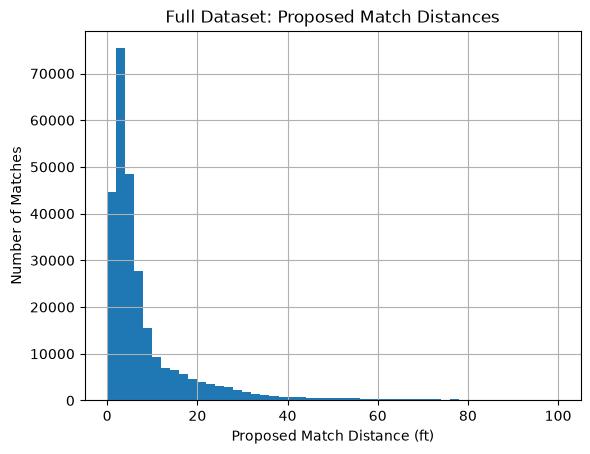

In [34]:
plt.hist(all_matches_df["distance_ft"], bins=50, range=(0, 100))

plt.xlabel("Proposed Match Distance (ft)")
plt.ylabel("Number of Matches")
plt.title("Full Dataset: Proposed Match Distances")
plt.grid()
plt.show()
#display the histogram of proposed match distances for the full dataset


In [35]:
threshold_ft = 40

accepted_matches_df = all_matches_df[
    all_matches_df["distance_ft"] < threshold_ft
].copy()

rejected_matches_df = all_matches_df[
    all_matches_df["distance_ft"] >= threshold_ft
].copy()

print("Accepted matches:", len(accepted_matches_df))
print("Rejected matches:", len(rejected_matches_df))

print(
    "Acceptance rate:",
    round(len(accepted_matches_df) / len(all_matches_df) * 100, 2),
    "%"
)
#display the acceptance rate of the matches based on the threshold

Accepted matches: 266928
Rejected matches: 13073
Acceptance rate: 95.33 %


In [36]:
unmatched_radar = len(radar) - len(accepted_matches_df)
unmatched_truth = len(truth) - len(accepted_matches_df)

print("Unmatched radar detections:", unmatched_radar)
print("Unmatched truth detections:", unmatched_truth)
#display the number of unmatched radar and truth detections

Unmatched radar detections: 15784
Unmatched truth detections: 125779


In [37]:
matched_df = accepted_matches_df.merge(
    radar,
    left_on=["timestamp", "radar_track_id"],
    right_on=["timestamp", "track_id"],
    how="left",
    validate="one_to_one"
)

matched_df.head()
#display the first few rows of the matched dataframe for our accepted matches

,timestamp,radar_track_id,truth_track_id,distance_ft,track_id,lat,lon,utm_x,utm_y,local_x_ft,local_y_ft,speed_mps,length_m,width_m,object_type,track_quality,lane_id
0,1.759512e+09,10258,3,28.067016,10258,32.661380,-97.274844,661779.974175,3.615063e+06,42.113449,284.974487,28.815837,7.403159,2.5,60,72.450371,3
1,1.759512e+09,10261,2,3.702690,10261,32.661351,-97.274548,661807.780701,3.615060e+06,27.790186,194.404053,30.437614,4.653116,2.5,30,72.125496,2
2,1.759512e+09,10262,1,2.040059,10262,32.661395,-97.274351,661826.167576,3.615066e+06,41.503681,133.218750,33.751753,4.721792,2.5,30,76.713287,3
3,1.759512e+09,10271,5,7.536070,10271,32.661344,-97.275081,661757.810174,3.615059e+06,31.796240,358.381409,29.503258,2.562120,2.5,30,70.684944,2
4,1.759512e+09,10258,3,30.140318,10258,32.661379,-97.274797,661784.389729,3.615063e+06,41.194061,270.516541,28.885696,7.403159,2.5,60,71.947105,3


In [38]:
matched_df = matched_df.merge(
    truth,
    left_on=["timestamp", "truth_track_id"],
    right_on=["timestamp", "track_id"],
    how="left",
    suffixes=("_radar", "_truth"),
    validate="one_to_one"
)

print("Matched rows:", len(matched_df))

matched_df[[
    "timestamp",
    "radar_track_id",
    "truth_track_id",
    "local_x_ft_radar",
    "local_x_ft_truth",
    "local_y_ft_radar",
    "local_y_ft_truth",
    "speed_mps_radar",
    "speed_mps_truth"
]].head()
#display the first few rows of the matched dataframe with both radar and truth data

Matched rows: 266928


,timestamp,radar_track_id,truth_track_id,local_x_ft_radar,local_x_ft_truth,local_y_ft_radar,local_y_ft_truth,speed_mps_radar,speed_mps_truth
0,1.759512e+09,10258,3,42.113449,42.755378,284.974487,313.034161,28.815837,30.483443
1,1.759512e+09,10261,2,27.790186,25.849874,194.404053,197.557639,30.437614,30.838051
2,1.759512e+09,10262,1,41.503681,39.832362,133.218750,134.388594,33.751753,34.430768
3,1.759512e+09,10271,5,31.796240,32.944414,358.381409,365.829499,29.503258,29.346869
4,1.759512e+09,10258,3,41.194061,42.226688,270.516541,300.639165,28.885696,28.765191


In [39]:
matched_df["x_error_m"] = (
    matched_df["local_x_ft_radar"] -
    matched_df["local_x_ft_truth"]
) * 0.3048

matched_df["y_error_m"] = (
    matched_df["local_y_ft_radar"] -
    matched_df["local_y_ft_truth"]
) * 0.3048

matched_df[[
    "radar_track_id",
    "truth_track_id",
    "x_error_m",
    "y_error_m"
]].head()
#display the first few rows of the matched dataframe with the calculated errors in meters

,radar_track_id,truth_track_id,x_error_m,y_error_m
0,10258,3,-0.195660,-8.552589
1,10261,2,0.591407,-0.961213
2,10262,1,0.509418,-0.356568
3,10271,5,-0.349963,-2.270178
4,10258,3,-0.314745,-9.181376


In [40]:
matched_df["position_error_m"] = np.sqrt(
    matched_df["x_error_m"]**2 +
    matched_df["y_error_m"]**2
)

matched_df[[
    "radar_track_id",
    "truth_track_id",
    "x_error_m",
    "y_error_m",
    "position_error_m"
]].head()
#display the first few rows of the matched dataframe with the calculated position errors in meters

,radar_track_id,truth_track_id,x_error_m,y_error_m,position_error_m
0,10258,3,-0.195660,-8.552589,8.554826
1,10261,2,0.591407,-0.961213,1.128580
2,10262,1,0.509418,-0.356568,0.621810
3,10271,5,-0.349963,-2.270178,2.296994
4,10258,3,-0.314745,-9.181376,9.186769


In [41]:
matched_df["speed_error_mps"] = (
    matched_df["speed_mps_radar"] -
    matched_df["speed_mps_truth"]
)

matched_df["abs_speed_error_mps"] = (
    matched_df["speed_error_mps"].abs()
)

matched_df[[
    "radar_track_id",
    "truth_track_id",
    "speed_mps_radar",
    "speed_mps_truth",
    "speed_error_mps",
    "abs_speed_error_mps"
]].head()
#display the first few rows of the matched dataframe with the calculated speed errors in meters per second

,radar_track_id,truth_track_id,speed_mps_radar,speed_mps_truth,speed_error_mps,abs_speed_error_mps
0,10258,3,28.815837,30.483443,-1.667606,1.667606
1,10261,2,30.437614,30.838051,-0.400437,0.400437
2,10262,1,33.751753,34.430768,-0.679015,0.679015
3,10271,5,29.503258,29.346869,0.156389,0.156389
4,10258,3,28.885696,28.765191,0.120505,0.120505


In [42]:
print("POSITION ACCURACY")
print(f"Mean error:       {matched_df['position_error_m'].mean()} m")
print(f"Median error:     {matched_df['position_error_m'].median()} m")
print(f"95th percentile:  {matched_df['position_error_m'].quantile(0.95)} m")

print("\nSPEED ACCURACY")
print(f"Mean absolute error:   {matched_df['abs_speed_error_mps'].mean()} m/s")
print(f"Median absolute error: {matched_df['abs_speed_error_mps'].median()} m/s")
print(f"Mean signed error:     {matched_df['speed_error_mps'].mean()} m/s")
#display the first few rows of the matched dataframe with the calculated summaries

POSITION ACCURACY
Mean error:       2.2037386837671837 m
Median error:     1.359881498640684 m
95th percentile:  7.591480398308704 m

SPEED ACCURACY
Mean absolute error:   1.2139229788093366 m/s
Median absolute error: 0.6380349999999999 m/s
Mean signed error:     -0.22301677629163386 m/s


In [43]:
position_rmse = np.sqrt(
    (matched_df["position_error_m"] ** 2).mean()
)

speed_rmse = np.sqrt(
    (matched_df["speed_error_mps"] ** 2).mean()
)

print(f"Position RMSE: {position_rmse} m")
print(f"Speed RMSE:    {speed_rmse} m/s")
#rmse error calculation for position and speed errors

Position RMSE: 3.1664111724671082 m
Speed RMSE:    2.844845693374897 m/s


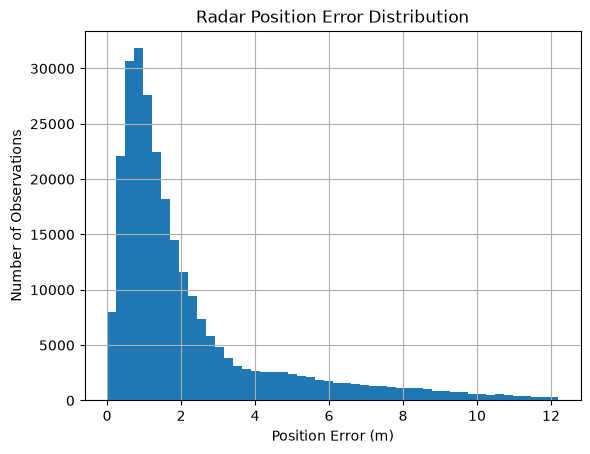

In [44]:
plt.hist(matched_df["position_error_m"], bins=50)

plt.xlabel("Position Error (m)")
plt.ylabel("Number of Observations")
plt.title("Radar Position Error Distribution")
plt.grid()
plt.show()
#display the histogram of position errors in meters

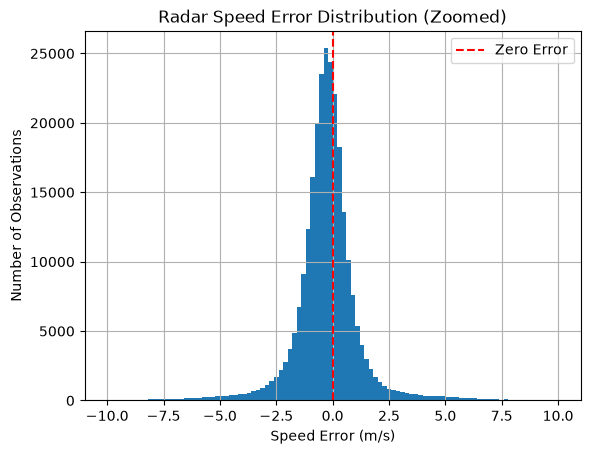

In [45]:
plt.hist(
    matched_df["speed_error_mps"].dropna(),
    bins=100,
    range=(-10, 10)
)

plt.axvline(0, color="red", linestyle="--", label="Zero Error")

plt.xlabel("Speed Error (m/s)")
plt.ylabel("Number of Observations")
plt.title("Radar Speed Error Distribution (Zoomed)")
plt.legend()
plt.grid()
plt.show()
#display the histogram of speed errors in meters per second

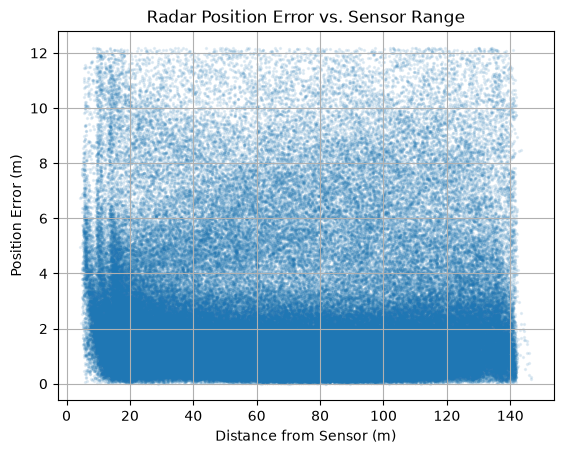

In [46]:
matched_df["range_m"] = np.sqrt(
    matched_df["local_x_ft_truth"]**2 +
    matched_df["local_y_ft_truth"]**2
) * 0.3048

plt.scatter(
    matched_df["range_m"],
    matched_df["position_error_m"],
    s=2,
    alpha=0.1
)

plt.xlabel("Distance from Sensor (m)")
plt.ylabel("Position Error (m)")
plt.title("Radar Position Error vs. Sensor Range")
plt.grid()
plt.show()
#display the scatter plot of position error vs. sensor range

In [47]:
matched_df["range_bin"] = (
    matched_df["range_m"] // 10 * 10
)

range_analysis = matched_df.groupby("range_bin")["position_error_m"].agg(
    ["mean", "median", "count"]
)

range_analysis
#display the analysis of position error statistics for 10m groupings

,mean,median,count
range_bin,,,
0.0,3.715184,3.147774,3624
10.0,2.636003,1.889912,21394
20.0,2.053333,1.377177,26427
30.0,1.985420,1.258164,25168
40.0,1.957330,1.188219,24342
50.0,1.943831,1.160179,23502
60.0,1.982662,1.152688,22738
70.0,1.992279,1.138160,21531
80.0,2.076035,1.188507,20375


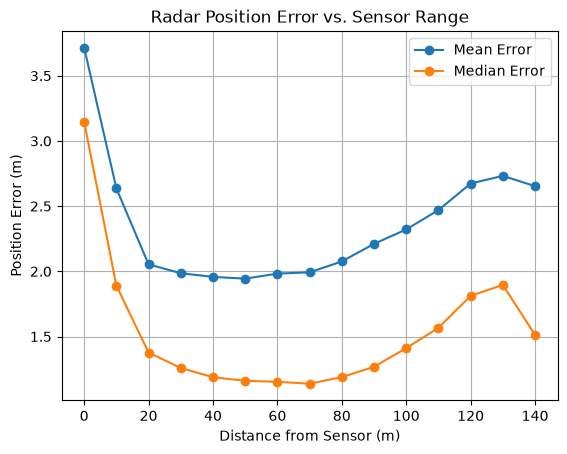

In [48]:
plt.plot(
    range_analysis.index,
    range_analysis["mean"],
    marker="o",
    label="Mean Error"
)

plt.plot(
    range_analysis.index,
    range_analysis["median"],
    marker="o",
    label="Median Error"
)

plt.xlabel("Distance from Sensor (m)")
plt.ylabel("Position Error (m)")
plt.title("Radar Position Error vs. Sensor Range")
plt.legend()
plt.grid()
plt.show()
#display the plot of mean and median position errors vs. sensor range

In [49]:
quality_analysis = matched_df.groupby("track_quality")["position_error_m"].agg(
    ["mean", "median", "count"]
)

quality_analysis.head(10)
#display the analysis of position error statistics for different track qualities

,mean,median,count
track_quality,,,
29.613188,1.333407,1.333407,1
31.347242,2.842526,2.842526,1
31.969299,1.547289,1.547289,1
32.062431,3.075609,3.075609,1
32.123928,3.096184,3.096184,1
33.229488,2.896585,2.896585,1
33.600666,1.463625,1.463625,1
33.693687,4.174871,4.174871,1
33.707001,0.873849,0.873849,1


In [50]:
matched_df["quality_bin"] = (
    matched_df["track_quality"] // 10 * 10
)

quality_analysis = matched_df.groupby("quality_bin")["position_error_m"].agg(
    ["mean", "median", "count"]
)

quality_analysis
#display the analysis of position error statistics for 10-unit groupings of track quality

,mean,median,count
quality_bin,,,
20.0,1.333407,1.333407,1
30.0,2.723851,1.948585,71
40.0,3.072652,2.376174,976
50.0,2.980865,2.069103,11050
60.0,2.686478,1.660275,93017
70.0,1.865217,1.202048,159309
80.0,2.026120,1.347143,2504


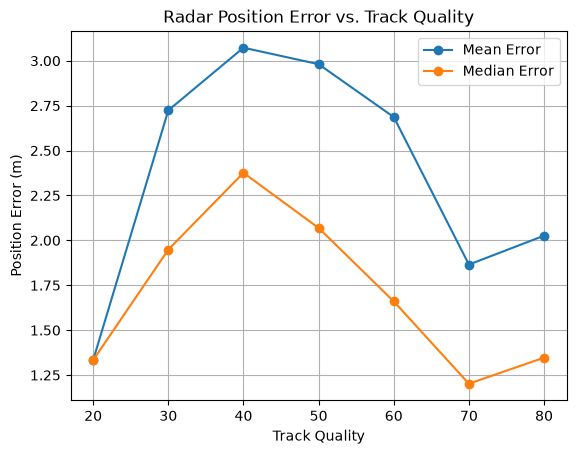

In [51]:
plt.plot(
    quality_analysis.index,
    quality_analysis["mean"],
    marker="o",
    label="Mean Error"
)

plt.plot(
    quality_analysis.index,
    quality_analysis["median"],
    marker="o",
    label="Median Error"
)

plt.xlabel("Track Quality")
plt.ylabel("Position Error (m)")
plt.title("Radar Position Error vs. Track Quality")
plt.legend()
plt.grid()
plt.show()
#visual of mean and median position errors vs. track quality

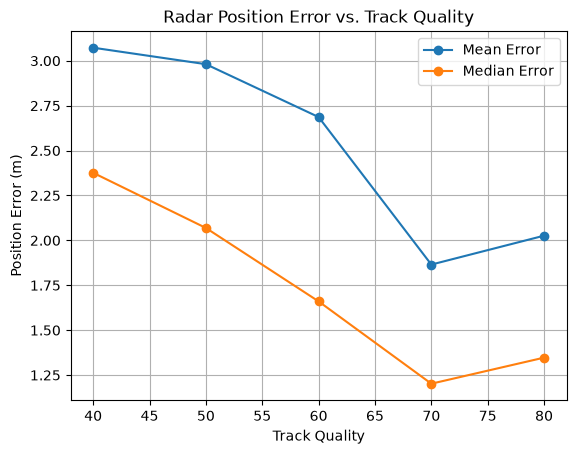

In [52]:
quality_analysis_filtered = quality_analysis[
    quality_analysis["count"] >= 100
]

plt.plot(
    quality_analysis_filtered.index,
    quality_analysis_filtered["mean"],
    marker="o",
    label="Mean Error"
)

plt.plot(
    quality_analysis_filtered.index,
    quality_analysis_filtered["median"],
    marker="o",
    label="Median Error"
)

plt.xlabel("Track Quality")
plt.ylabel("Position Error (m)")
plt.title("Radar Position Error vs. Track Quality")
plt.legend()
plt.grid()
plt.show()
#visual of mean and median position errors vs. track quality for track qualities with at least 100 samples

In [53]:
lane_analysis = matched_df.groupby("lane_id")["position_error_m"].agg(
    ["mean", "median", "count"]
)

lane_analysis
#display the analysis of position error statistics for different lanes

,mean,median,count
lane_id,,,
1,3.025779,1.838029,4391
2,2.246186,1.326840,114163
3,2.521132,1.525595,86541
4,1.622770,1.209877,61833


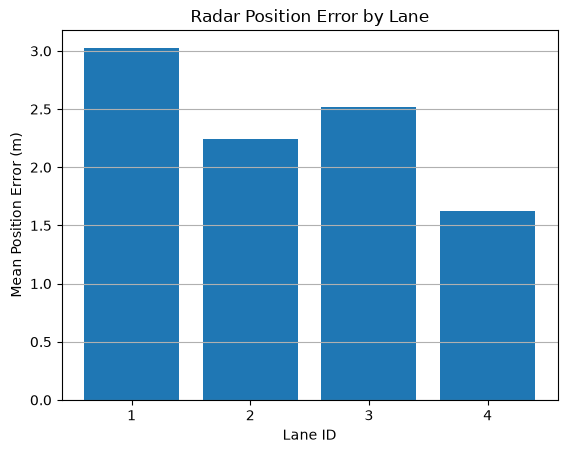

In [54]:
plt.bar(
    lane_analysis.index,
    lane_analysis["mean"]
)

plt.xlabel("Lane ID")
plt.ylabel("Mean Position Error (m)")
plt.title("Radar Position Error by Lane")
plt.xticks(lane_analysis.index)
plt.grid(axis="y")
plt.show()
#visual of mean position error by lane

In [55]:
thresholds = [10, 20, 30, 40, 50, 60]

for threshold in thresholds:
    subset = matched_df[
        matched_df["distance_ft"] < threshold
    ]

    print(
        f"{threshold} ft | "
        f"Matches: {len(subset)} | "
        f"Mean position error: {subset['position_error_m'].mean()} m"
    )
#display the analysis of position error statistics for different distance thresholds

10 ft | Matches: 211733 | Mean position error: 1.2233957226790944 m
20 ft | Matches: 244670 | Mean position error: 1.646228285143861 m
30 ft | Matches: 260382 | Mean position error: 1.997269511176697 m
40 ft | Matches: 266928 | Mean position error: 2.2037386837671837 m
50 ft | Matches: 266928 | Mean position error: 2.2037386837671837 m
60 ft | Matches: 266928 | Mean position error: 2.2037386837671837 m


In [56]:
track_consistency = (
    accepted_matches_df
    .groupby("radar_track_id")["truth_track_id"]
    .nunique()
)

print("Radar tracks analyzed:", len(track_consistency))
print("Tracks matched to one truth ID:", (track_consistency == 1).sum())
print("Tracks matched to multiple truth IDs:", (track_consistency > 1).sum())
#display the analysis of track consistency for radar tracks

Radar tracks analyzed: 5368
Tracks matched to one truth ID: 3928
Tracks matched to multiple truth IDs: 1440


In [57]:
matched_df.to_csv("../output/matched_results.csv", index=False)

matched_df.to_excel("../output/matched_results.xlsx", index=False)

print("Results exported successfully!")
#export the matched results to CSV and Excel files

Results exported successfully!
